# Synthetic S-curves for DGSA

Latin hypercube sample of the three S-curve parameters, anchored at $t_0$ = 2026. S-curve formulation:

$$C(t) = \frac{L}{1 + (L/C_0 - 1)\,e^{-k(t-t_0)}}$$

We sample $\log_{10}(C_0/L)$, $k$, and $\log_{10}L$, where $C_0$ is the reference capacity at $t_0$, $L$ is the saturation capacity, and $k$ is the growth rate metric. 

Outputs:
- `manifest.csv` (params -- one row per `schedule_name`)
- `curves.csv` (year x `schedule_name`; in Mt CO2/yr)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import curve_fit
from scipy.stats import qmc

## Config

In [ ]:
# --- [ sampled S-curve params: uniform in each dim (so log10 dims are log-uniform) ] ---
PARAM_BOUNDS = {
    "log10_C0_over_L": (np.log10(5e-6), np.log10(0.05)),  # [-]           ~cdr.fyi deliveries at L_gcam -> ~1x GCAM's own fit
    "k":               (0.025, 0.25),                     # [yr^-1]       ~Nemet low-dist -> GCAM first-decade rate
    "log10_L":         (np.log10(200), np.log10(5000)),  # [Mt CO2/yr]
}
T0 = 2026           # year C0 is anchored to
N_PER_GEOCHEM = 12  # S-curve draws per geochem draw (N = N_PER_GEOCHEM * n_geochem)
RANDOM_SEED = 2026  

# --- [ geochem DGSA batch to pair with ] ---
DGSA_VERSION = "v1.2"
EXP_GROUP = f"gcam_dgsa_{DGSA_VERSION}"
EXP_SET = "exe_central1p5"
BATCH_CSV = ("s3://carbonplan-carbon-removal/ew-workflows-data/scepter/batch/"
             f"{EXP_GROUP}_{EXP_SET}_gbas_yearly_ltm_v4_repcells1.csv")
COLLAPSE_COLS = ["dustrad", "cec_factor", "apprate_base", "qrun_factor"]  # same order as cdr-gcam-by-region.ipynb

# --- [ donor GCAM schedule: year grid + reference fit ] ---
S3_BASE = "s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region"
DONOR_PKL = f"{S3_BASE}/{EXP_SET}/5.0-tHaYr-appRate-FIXED/annual_rockflx_densest-ag-region_1deg.pkl"

# --- [ save ] ---
SAVE_TO_S3 = True
OVERWRITE_EXISTING = False
S3_SAVE_DIR = f"{S3_BASE}/synthetic-dgsa-{DGSA_VERSION}"
manifest_fn = f"{S3_SAVE_DIR}/manifest.csv"
curves_fn = f"{S3_SAVE_DIR}/curves.csv"

## Geochem draws to pair with

In [10]:
dfb = pd.read_csv(BATCH_CSV)
df_treat = dfb[dfb["dustrate"] != 0]
assert (df_treat.groupby("lhs_sample_id")[COLLAPSE_COLS].nunique() == 1).all().all(), "geochem params vary across sites"

df_geo = (df_treat.drop_duplicates("lhs_sample_id").sort_values("lhs_sample_id")
          [["lhs_sample_id"] + COLLAPSE_COLS].reset_index(drop=True))
# same string cdr-gcam-by-region.ipynb builds, so the scaling step can match on it
df_geo["collapsed_inputs"] = df_geo[COLLAPSE_COLS].apply(
    lambda row: " | ".join(f"{col}={row[col]}" for col in COLLAPSE_COLS), axis=1
)
n_geo = len(df_geo)
print(f"{n_geo} geochem draws")

250 geochem draws


## GCAM reference point
Where the donor schedule's best fit sits in the sampled space.

In [11]:
def logistic(t, C0, L, k, t0):
    return L / (1 + (L / C0 - 1) * np.exp(-k * (t - t0)))


df_donor = pd.read_pickle(DONOR_PKL)
years = np.sort(df_donor["time"].unique()).astype(float)
donor_global = df_donor.groupby("time")["gcam_gross_cdr_mtCO2"].sum().reindex(years).values

(C0_fit, L_fit, k_fit), _ = curve_fit(
    lambda t, C0, L, k: logistic(t, C0, L, k, T0), years, donor_global,
    p0=[max(np.interp(T0, years, donor_global), 1e-6), donor_global.max() * 3, 0.2],
    bounds=([1e-9, donor_global.max(), 1e-4], [np.inf, np.inf, 2.0]), maxfev=20000,
)
gcam_ref = {"log10_C0_over_L": np.log10(C0_fit / L_fit), "k": k_fit, "log10_L": np.log10(L_fit)}

print(f"{EXP_SET} fit: C0={C0_fit:,.1f}  L={L_fit:,.1f} Mt CO2/yr  k={k_fit:.3f} yr^-1")
for p, v in gcam_ref.items():
    lo, hi = PARAM_BOUNDS[p]
    print(f"  {p:16s} {v:7.3f}   bounds [{lo:.3f}, {hi:.3f}]" + ("" if lo <= v <= hi else "   <-- outside"))

exe_central1p5 fit: C0=213.4  L=4,630.9 Mt CO2/yr  k=0.240 yr^-1
  log10_C0_over_L   -1.336   bounds [-5.301, -1.301]
  k                  0.240   bounds [0.025, 0.250]
  log10_L            3.666   bounds [2.301, 3.699]


## Latin hypercube sample

In [12]:
names = list(PARAM_BOUNDS)
lo, hi = np.array(list(PARAM_BOUNDS.values())).T
n = N_PER_GEOCHEM * n_geo
unit = qmc.LatinHypercube(d=len(names), seed=RANDOM_SEED).random(n=n)

manifest = pd.DataFrame(qmc.scale(unit, lo, hi), columns=names)
manifest["L"] = 10 ** manifest["log10_L"]
manifest["C0"] = 10 ** manifest["log10_C0_over_L"] * manifest["L"]
manifest["t0"] = T0
# sample j -> geochem draw j mod n_geo (both LHS row orders are random)
manifest = pd.concat([manifest, df_geo.iloc[np.arange(n) % n_geo].reset_index(drop=True)], axis=1)
manifest.index = pd.Index([f"scurve{j:04d}" for j in range(n)], name="schedule_name")
manifest#.head()

,log10_C0_over_L,k,log10_L,L,C0,t0,lhs_sample_id,dustrad,cec_factor,apprate_base,qrun_factor,collapsed_inputs
schedule_name,,,,,,,,,,,,
scurve0000,-3.979935,0.063202,3.259333,1816.908781,0.190282,2026,0,3.892094,2.776353,8.850703,1.119041,dustrad=3.892094324720439 | cec_factor=2.77635...
scurve0001,-4.762857,0.216748,2.357045,227.533428,0.003928,2026,1,6.871099,3.579180,13.498141,2.940011,dustrad=6.871098902122714 | cec_factor=3.57918...
scurve0002,-4.446237,0.080412,2.763910,580.643988,0.020781,2026,2,0.908745,3.790174,18.089053,0.410106,dustrad=0.9087454280605216 | cec_factor=3.7901...
scurve0003,-4.833428,0.156177,3.651943,4486.868818,0.065844,2026,3,4.277703,1.834365,5.613806,2.260913,dustrad=4.277703382166453 | cec_factor=1.83436...
scurve0004,-4.364544,0.161969,3.665179,4625.720553,0.199818,2026,4,0.341304,2.735404,2.136077,3.175003,dustrad=0.3413041724759717 | cec_factor=2.7354...
...,...,...,...,...,...,...,...,...,...,...,...,...
scurve2995,-1.533361,0.138680,2.628749,425.352318,12.456267,2026,245,8.354275,0.134034,5.032103,1.785260,dustrad=8.354274879611005 | cec_factor=0.13403...
scurve2996,-1.797285,0.167968,2.942965,876.930269,13.985570,2026,246,9.016744,3.283638,5.415092,0.343537,dustrad=9.016743969591326 | cec_factor=3.28363...
scurve2997,-3.796985,0.244191,3.291675,1957.381123,0.312385,2026,247,16.588339,3.098406,8.647282,0.623316,dustrad=16.58833888600782 | cec_factor=3.09840...


## Build the curves

In [13]:
curves = pd.DataFrame(
    logistic(years[:, None], manifest["C0"].values, manifest["L"].values, manifest["k"].values, T0),
    index=pd.Index(years, name="year"), columns=manifest.index,
)
assert np.isfinite(curves.values).all() and (curves.values > 0).all()
assert (np.diff(curves.values, axis=0) >= 0).all()

manifest["t_mid"] = T0 + np.log(manifest["L"] / manifest["C0"] - 1) / manifest["k"]  # year C reaches L/2
manifest["C_end_over_L"] = curves.iloc[-1].values / manifest["L"].values  # saturation at end of horizon
manifest["cum_mtco2"] = np.trapezoid(curves.values, years, axis=0)
print(f"{curves.shape[1]} curves x {curves.shape[0]} years ({years[0]:.0f}-{years[-1]:.0f})")
manifest[names + ["C0", "L", "t_mid", "C_end_over_L", "cum_mtco2"]].describe().T

3000 curves x 81 years (2020-2100)


,count,mean,std,min,25%,50%,75%,max
log10_C0_over_L,3000.0,-3.301026,1.154900,-5.300069,-4.300440,-3.301091,-2.301760,-1.301350
k,3000.0,0.137499,0.064963,0.025039,0.081294,0.137502,0.193709,0.249967
log10_L,3000.0,2.999996,0.403618,2.301289,2.650546,3.000050,3.349456,3.698588
C0,3000.0,7.932558,21.064396,0.001104,0.050872,0.481826,4.792430,224.456607
L,3000.0,1491.188161,1286.058243,200.119398,447.245851,1000.115929,2235.920742,4995.604590
t_mid,3000.0,2104.298229,67.798293,2038.291769,2062.307663,2081.634037,2120.256946,2499.517112
C_end_over_L,3000.0,0.652340,0.411631,0.000041,0.155923,0.925896,0.998907,1.000000
cum_mtco2,3000.0,32222.912518,45887.162055,0.647790,1965.954291,13150.729462,42155.223445,271294.928852


## QC plots

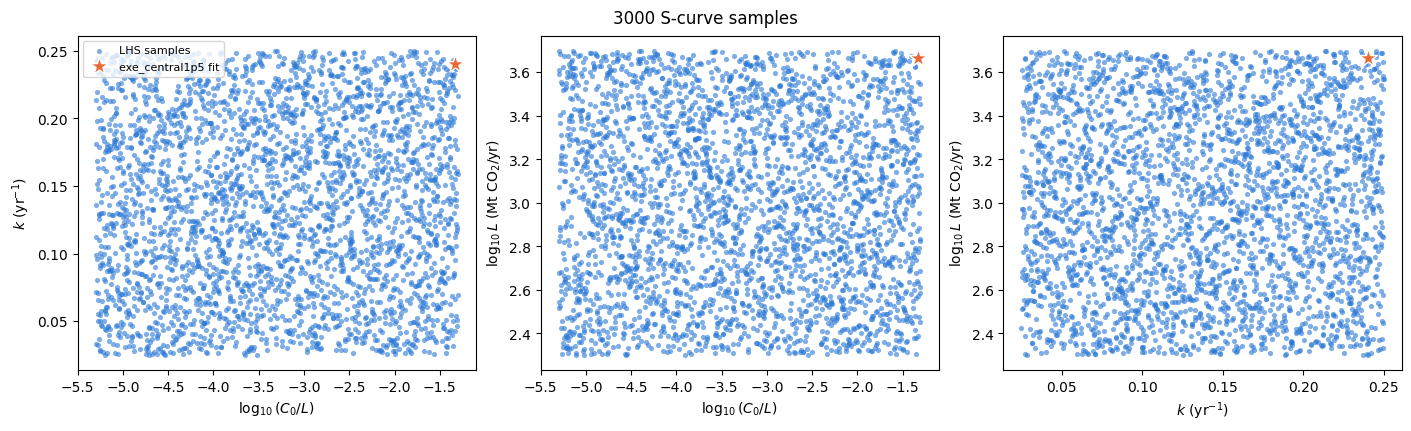

In [14]:
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#333333"
labels = {
    "log10_C0_over_L": r"$\log_{10}(C_0/L)$",
    "k": r"$k$ (yr$^{-1}$)",
    "log10_L": r"$\log_{10}L$ (Mt CO$_2$/yr)",
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout="constrained")
for ax, (x, y) in zip(axes, [("log10_C0_over_L", "k"), ("log10_C0_over_L", "log10_L"), ("k", "log10_L")]):
    ax.scatter(manifest[x], manifest[y], s=14, color=BLUE, alpha=0.6, lw=0, label="LHS samples")
    ax.scatter(gcam_ref[x], gcam_ref[y], s=180, marker="*", color=ORANGE, edgecolor="white", lw=1,
               zorder=3, label=f"{EXP_SET} fit")
    ax.set_xlabel(labels[x])
    ax.set_ylabel(labels[y])
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(f"{n} S-curve samples")
plt.show()

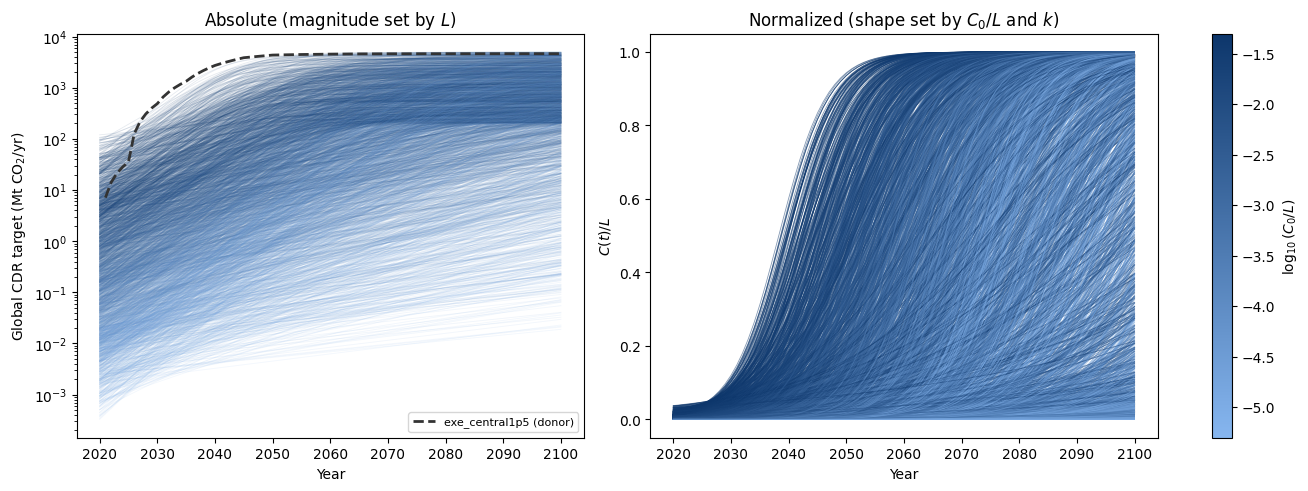

In [15]:
cmap = LinearSegmentedColormap.from_list("blue_seq", ["#86b6ef", "#0d366b"])
norm = plt.Normalize(*PARAM_BOUNDS["log10_C0_over_L"])
colors = cmap(norm(manifest["log10_C0_over_L"].values))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for j, name in enumerate(curves.columns):
    axes[0].plot(years, curves[name], color=colors[j], lw=0.6, alpha=0.1)
    axes[1].plot(years, curves[name] / manifest.loc[name, "L"], color=colors[j], lw=0.6, alpha=0.5)
axes[0].plot(years, np.where(donor_global > 0, donor_global, np.nan), color=INK, ls="--", lw=2, label=f"{EXP_SET} (donor)")
axes[0].set_yscale("log")
axes[0].set_ylabel(r"Global CDR target (Mt CO$_2$/yr)")
axes[0].set_title("Absolute (magnitude set by $L$)")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].set_ylabel("$C(t)/L$")
axes[1].set_title("Normalized (shape set by $C_0/L$ and $k$)")
for ax in axes:
    ax.set_xlabel("Year")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, label=labels["log10_C0_over_L"])
plt.show()

## Save
Dry run unless `SAVE_TO_S3 = True`.

In [16]:
fs = s3fs.S3FileSystem()

if SAVE_TO_S3:
    if not OVERWRITE_EXISTING:
        existing = [fn for fn in (manifest_fn, curves_fn) if fs.exists(fn.replace("s3://", ""))]
        if existing:
            raise FileExistsError("refusing to overwrite (set OVERWRITE_EXISTING = True):\n  " + "\n  ".join(existing))
    manifest.to_csv(manifest_fn)
    curves.to_csv(curves_fn)

    pd.testing.assert_frame_equal(pd.read_csv(manifest_fn, index_col="schedule_name"), manifest)
    pd.testing.assert_frame_equal(pd.read_csv(curves_fn, index_col="year").rename_axis(columns="schedule_name"), curves)
    print(f"saved + round-trip checked:\n  {manifest_fn}\n  {curves_fn}")
else:
    print(f"SAVE_TO_S3 is False -- nothing written. Would write:\n  {manifest_fn}\n  {curves_fn}")

saved + round-trip checked:
  s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region/synthetic-dgsa-v1.2/manifest.csv
  s3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/one-cell-per-region/synthetic-dgsa-v1.2/curves.csv


In [ ]:
# ---